# TriageAI — Phase 1: Data Understanding, EDA & Leakage-Safe Splitting

**Project:** TriageAI – Confidence-Aware Support Ticket Classification with Human-in-the-Loop Routing
**Phase 1 owner:** Farah Hany · **Notebook completed and reorganised for hand-off to Phase 2 (Preprocessing, TF-IDF & MLflow)**

**Task:** predict `queue` (department) from `subject + body` of English tickets only.
**Dataset:** Customer IT Support – Ticket Dataset (Tobias Bueck / Softoft, Kaggle).

## What this notebook does

| # | Section | Brief reference |
|---|---|---|
| 0 | Config & imports | – |
| 1 | Load raw data | 4.1 |
| 2 | English subset | 3 |
| 3 | Missing values, empty text, text construction | 4.2 |
| 4 | Class distribution | 4.4 |
| 5 | Text analysis | 4.5 |
| 6 | Label sanity check (manual look) | – |
| 7 | Exact duplicates | 4.3 |
| 8 | Near duplicates (TF-IDF cosine) + threshold sweep + review samples | 4.3 |
| 9 | Threshold decision, duplicate groups, policy | 4.3 / 5.4 |
| 10 | Group-aware stratified split | 5.6 |
| 11 | Leakage verification + comparison with a plain stratified split | 5.4 / 5.5 |
| 12 | Save datasets | 5 |
| 13 | Data Quality Summary | 4.6 |
| 14 | Hand-off notes for Phase 2 | – |

> **Important – one decision is still open:** the near-duplicate cosine threshold (`NEAR_DUP_THRESHOLD`) is set to a **provisional** value so the notebook runs end to end.
> Per the brief, it must be confirmed after manually reviewing `near_duplicate_review_samples.csv` (Section 8). After confirming, set `THRESHOLD_CONFIRMED = True` and re-run from Section 9.

In [40]:
import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# ------------------------------ configuration ------------------------------
RAW_FILENAME = "aa_dataset-tickets-multi-lang-5-2-50-version.csv"
LANGUAGE = "en"
RANDOM_STATE = 42
OUTPUT_DIR = Path("phase1_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Near-duplicate definition: cosine similarity on TF-IDF vectors >= threshold.
NEAR_DUP_THRESHOLD = 0.70     # PROVISIONAL - confirm after manual review (Section 8)
THRESHOLD_CONFIRMED = True   # set to True once the team has reviewed the samples
SWEEP_THRESHOLDS = [0.70,0.80, 0.85, 0.90, 0.95, 0.99]
MIN_PAIR_SIM = min(SWEEP_THRESHOLDS)
PAIRS_PER_BAND = 15            # pairs sampled per similarity band for manual review

# Split: 20 group-aware stratified folds -> 14 train / 3 val / 3 test (70/15/15 target)
N_SPLITS, TRAIN_FOLDS, VAL_FOLDS = 20, 14, 3

dq = {}  # collects every number needed for the Data Quality Summary (Section 13)

## 1. Load raw data (Brief 4.1)

In [41]:
raw = pd.read_csv(RAW_FILENAME)

dq["records_raw"] = len(raw)

print("Loaded:", RAW_FILENAME, "| shape:", raw.shape)

display(raw.head())

Loaded: aa_dataset-tickets-multi-lang-5-2-50-version.csv | shape: (28587, 16)


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte einen gravierenden Sicherheitsvorfall melden, der gegenwärtig mehrere Komp...",Vielen Dank für die Meldung des kritischen Sicherheitsvorfalls und die Bereitstellung der Übersicht über die betroff...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management ...","Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account management system, ...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Features,"Dear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed informati...","Thank you for your inquiry. Our products support integration with Amazon Alexa, Google Assistant, and Apple HomeKit....",Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this message finds you well. I am reaching out to request clarification about ...",We appreciate you reaching out with your billing questions. The billing period generally begins on the first day of ...,Request,Billing and Payments,low,en,51,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compatibility,"Dear Support Team,\n\nI hope this message reaches you well. I am reaching out to ask about the compatibility of your...","Thank you for your inquiry. Our product supports integration with major CRM, email marketing, and analytics platform...",Problem,Sales and Pre-Sales,medium,en,51,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN


In [42]:
raw.info()
display(raw.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28587 entries, 0 to 28586
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   subject   24749 non-null  object
 1   body      28587 non-null  object
 2   answer    28580 non-null  object
 3   type      28587 non-null  object
 4   queue     28587 non-null  object
 5   priority  28587 non-null  object
 6   language  28587 non-null  object
 7   version   28587 non-null  int64 
 8   tag_1     28587 non-null  object
 9   tag_2     28574 non-null  object
 10  tag_3     28451 non-null  object
 11  tag_4     25529 non-null  object
 12  tag_5     14545 non-null  object
 13  tag_6     5874 non-null   object
 14  tag_7     2040 non-null   object
 15  tag_8     565 non-null    object
dtypes: int64(1), object(15)
memory usage: 3.5+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
subject,24749,24749,Wesentlicher Sicherheitsvorfall,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body,28587,28587,"Sehr geehrtes Support-Team,\n\nich möchte einen gravierenden Sicherheitsvorfall melden, der gegenwärtig mehrere Komp...",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
answer,28580,28580,Vielen Dank für die Meldung des kritischen Sicherheitsvorfalls und die Bereitstellung der Übersicht über die betroff...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,28587,4,Incident,11466,NaN,NaN,NaN,NaN,NaN,NaN,NaN
queue,28587,10,Technical Support,8362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
priority,28587,3,medium,11515,NaN,NaN,NaN,NaN,NaN,NaN,NaN
language,28587,2,en,16338,NaN,NaN,NaN,NaN,NaN,NaN,NaN
version,28587.0,NaN,NaN,NaN,278.382027,165.962935,51.0,52.0,400.0,400.0,400.0
tag_1,28587,116,Security,5880,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tag_2,28574,256,Performance,5903,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. English subset (Brief 3)
Only English tickets are used. `raw_row_id` keeps the row number from the original CSV for traceability.

In [43]:
print(raw["language"].value_counts())

df = raw[raw["language"] == LANGUAGE].copy()
df["raw_row_id"] = df.index
df.reset_index(drop=True, inplace=True)

dq["records_english"] = len(df)

print(f"Before: {len(raw)} -> After: {len(df)}")

assert df["language"].nunique() == 1

language
en    16338
de    12249
Name: count, dtype: int64
Before: 28587 -> After: 16338


## 3. Missing values, empty text and text construction (Brief 4.2)

Rules (from the brief):
* A ticket with a missing/empty **subject** is **kept** if the **body** is usable.
* A ticket is rejected only if there is **no classifiable text** (subject and body both empty/whitespace).
* Columns that are not model inputs (`answer`, `type`, `priority`, `tag_*`, `version`) are excluded to avoid data leakage.

In [44]:
# Missing values
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2)
})
display(missing)

dq["missing_subject"] = df["subject"].isnull().sum()
dq["missing_body"] = df["body"].isnull().sum()

# Clean text
df["subject"] = df["subject"].fillna("").str.strip()
df["body"] = df["body"].fillna("").str.strip()

# Count empty values
dq["empty_subject_after_strip"] = (df["subject"] == "").sum()
dq["empty_body_after_strip"] = (df["body"] == "").sum()

# Combine subject and body
df["text"] = (df["subject"] + " " + df["body"]).str.strip()

# Detect empty tickets
empty_text_mask = df["text"] == ""
dq["empty_text_records"] = empty_text_mask.sum()

print("Empty subject:", dq["empty_subject_after_strip"])
print("Empty body:", dq["empty_body_after_strip"])
print("Empty text:", dq["empty_text_records"], "(no classifiable text -> removed)")

,missing_count,missing_%
subject,2607,15.96
body,0,0.00
answer,3,0.02
type,0,0.00
queue,0,0.00
priority,0,0.00
language,0,0.00
version,0,0.00
tag_1,0,0.00
tag_2,6,0.04


Empty subject: 2607
Empty body: 0
Empty text: 0 (no classifiable text -> removed)


In [45]:
dq["dropped_empty_text"] = int(empty_text_mask.sum())
df = df[~empty_text_mask].reset_index(drop=True)
df["ticket_id"] = np.arange(len(df))          # positional id used everywhere below
dq["records_final"] = len(df)
print("Records kept for modelling:", f"{len(df):,}")
display(df[["ticket_id", "subject", "body", "text", "queue"]].head())

Records kept for modelling: 16,338


,ticket_id,subject,body,text,queue
0,0,Account Disruption,"Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management ...","Account Disruption Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized ...",Technical Support
1,1,Query About Smart Home System Integration Features,"Dear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed informati...","Query About Smart Home System Integration Features Dear Customer Support Team,\n\nI hope this message reaches you we...",Returns and Exchanges
2,2,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this message finds you well. I am reaching out to request clarification about ...","Inquiry Regarding Invoice Details Dear Customer Support Team,\n\nI hope this message finds you well. I am reaching o...",Billing and Payments
3,3,Question About Marketing Agency Software Compatibility,"Dear Support Team,\n\nI hope this message reaches you well. I am reaching out to ask about the compatibility of your...","Question About Marketing Agency Software Compatibility Dear Support Team,\n\nI hope this message reaches you well. I...",Sales and Pre-Sales
4,4,Feature Query,"Dear Customer Support,\n\nI hope this message reaches you in good health. I am eager to learn more about the feature...","Feature Query Dear Customer Support,\n\nI hope this message reaches you in good health. I am eager to learn more abo...",Technical Support


## 4. Class distribution (Brief 4.4)

,tickets,percent
queue,,
Technical Support,4737,28.99
Product Support,3073,18.81
Customer Service,2410,14.75
IT Support,1942,11.89
Billing and Payments,1595,9.76
Returns and Exchanges,820,5.02
Service Outages and Maintenance,664,4.06
Sales and Pre-Sales,513,3.14
Human Resources,348,2.13


Number of queues : 10
Largest queue    : Technical Support (4,737)
Smallest queue   : General Inquiry (236)
Imbalance ratio  : 20.1 : 1


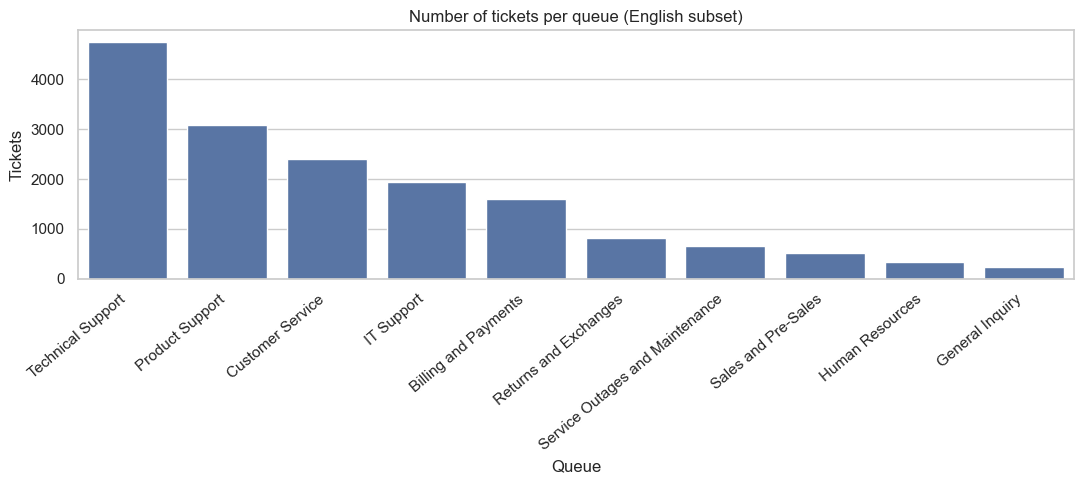

In [46]:
class_counts = df["queue"].value_counts()
class_dist = pd.DataFrame({
    "tickets": class_counts,
    "percent": (class_counts / class_counts.sum() * 100).round(2),
})
display(class_dist)

largest, smallest = class_counts.index[0], class_counts.index[-1]
imbalance_ratio = class_counts.iloc[0] / class_counts.iloc[-1]
print(f"Number of queues : {class_counts.shape[0]}")
print(f"Largest queue    : {largest} ({class_counts.iloc[0]:,})")
print(f"Smallest queue   : {smallest} ({class_counts.iloc[-1]:,})")
print(f"Imbalance ratio  : {imbalance_ratio:.1f} : 1")

dq["n_classes"] = int(class_counts.shape[0])
dq["class_distribution"] = class_dist.reset_index().rename(columns={"queue": "queue"}).to_dict("records")
dq["largest_queue"] = {"name": largest, "tickets": int(class_counts.iloc[0])}
dq["smallest_queue"] = {"name": smallest, "tickets": int(class_counts.iloc[-1])}
dq["imbalance_ratio"] = round(float(imbalance_ratio), 1)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax, color="#4C72B0")
ax.set_title("Number of tickets per queue (English subset)")
ax.set_xlabel("Queue"); ax.set_ylabel("Tickets")
plt.xticks(rotation=40, ha="right")
plt.tight_layout(); plt.show()

## 5. Text analysis (Brief 4.5)
Length, word count, most frequent words, and common terms per queue.

,subject_length,body_length,text_length,word_count
count,16338.0,16338.0,16338.0,16338.0
mean,36.7,367.9,405.4,58.6
std,21.4,179.9,179.7,26.9
min,0.0,6.0,18.0,2.0
25%,27.0,214.0,254.2,36.0
50%,39.0,377.0,416.0,60.0
75%,50.0,533.0,565.0,82.0
max,234.0,1147.0,1189.0,172.0


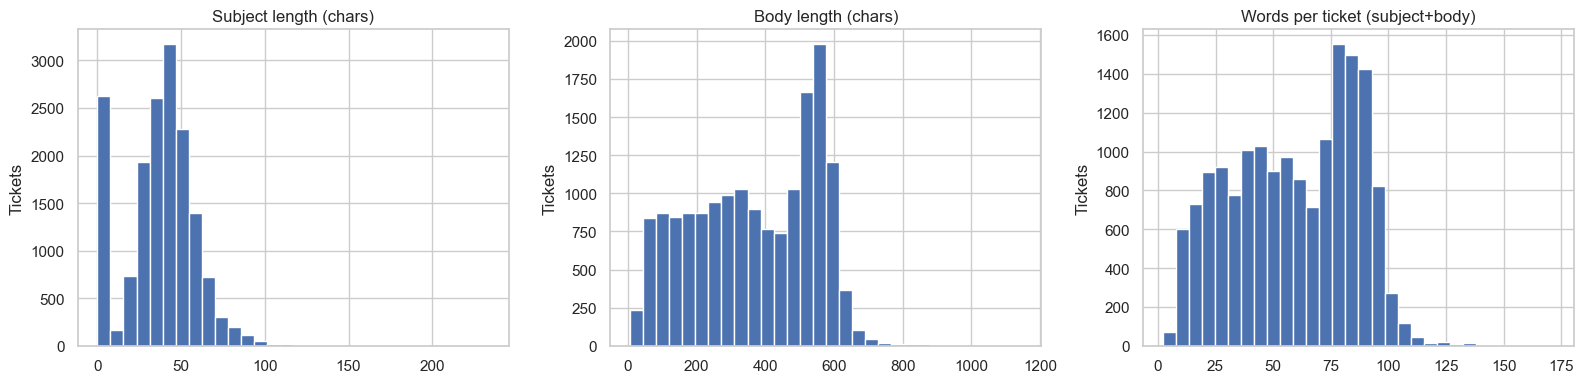

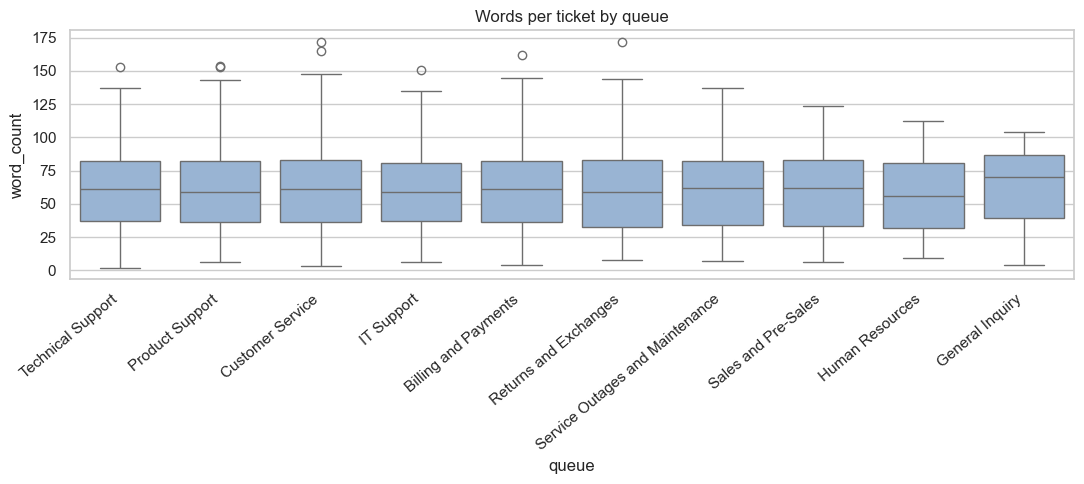

In [47]:
df["subject_length"] = df["subject"].str.len()
df["body_length"] = df["body"].str.len()
df["text_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

display(df[["subject_length", "body_length", "text_length", "word_count"]].describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes,
                          ["subject_length", "body_length", "word_count"],
                          ["Subject length (chars)", "Body length (chars)", "Words per ticket (subject+body)"]):
    ax.hist(df[col], bins=30, color="#4C72B0")
    ax.set_title(title); ax.set_ylabel("Tickets")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
order = class_counts.index
sns.boxplot(data=df, x="queue", y="word_count", order=order, ax=ax, color="#8FB4DD")
ax.set_title("Words per ticket by queue")
plt.xticks(rotation=40, ha="right")
plt.tight_layout(); plt.show()

dq["text_length_stats"] = df["text_length"].describe().round(1).to_dict()
dq["word_count_stats"] = df["word_count"].describe().round(1).to_dict()

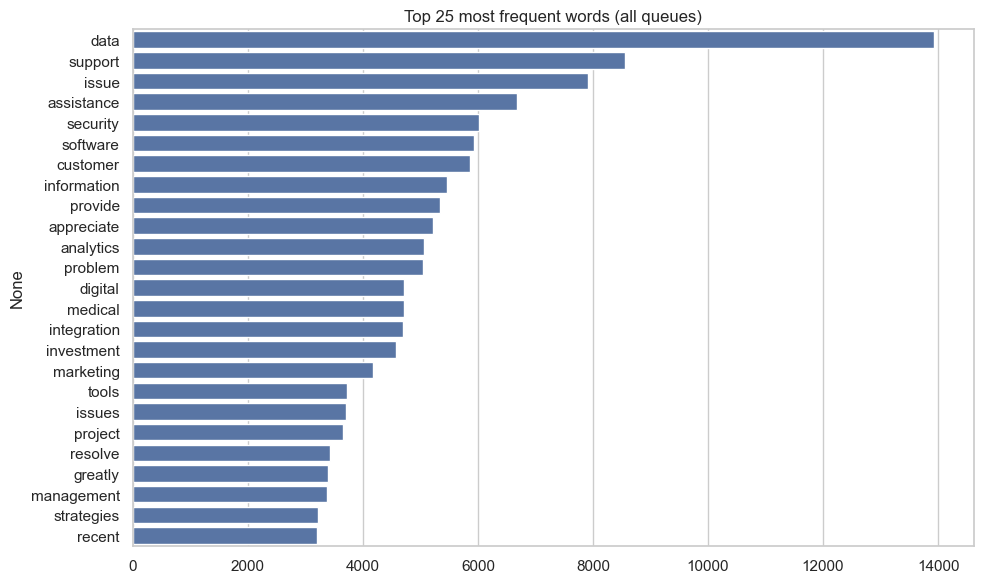

In [48]:
# Most frequent words overall (English stop words removed)
cv = CountVectorizer(stop_words="english", lowercase=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
counts = cv.fit_transform(df["text"])
freq = pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
top_words = freq.sort_values(ascending=False).head(25)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_words.values, y=top_words.index, ax=ax, color="#4C72B0")
ax.set_title("Top 25 most frequent words (all queues)")
plt.tight_layout(); plt.show()
dq["top_words_overall"] = top_words.head(15).to_dict()

In [49]:
# Common terms per queue: highest mean TF-IDF inside each queue.
# max_df=0.5 removes words that appear in more than half of all tickets (e.g. greetings).
tf_terms = TfidfVectorizer(stop_words="english", max_df=0.5, min_df=3, sublinear_tf=True,
                           token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
Xt = tf_terms.fit_transform(df["text"])
terms = np.array(tf_terms.get_feature_names_out())

top_terms = {}
for q in class_counts.index:
    mask = (df["queue"] == q).to_numpy()
    mean_scores = np.asarray(Xt[mask].mean(axis=0)).ravel()
    top_terms[q] = ", ".join(terms[np.argsort(mean_scores)[::-1][:10]])

terms_per_queue = pd.Series(top_terms, name="top_terms").to_frame()
display(terms_per_queue)
dq["top_terms_per_queue"] = top_terms

,top_terms
Technical Support,"data, issue, software, problem, security, assistance, issues, support, analytics, medical"
Product Support,"data, issue, security, analytics, assistance, digital, support, integration, investment, software"
Customer Service,"data, support, information, analytics, investment, strategies, integration, provide, assistance, digital"
IT Support,"data, software, issue, problem, tools, assistance, support, analytics, security, digital"
Billing and Payments,"billing, payment, information, provide, details, data, support, services, appreciate, assistance"
Returns and Exchanges,"data, investment, security, software, information, analytics, medical, support, digital, brand"
Service Outages and Maintenance,"service, outage, outages, impacting, disruptions, network, disruption, data, server, issue"
Sales and Pre-Sales,"data, integration, information, saas, brand, strategies, provide, medical, support, digital"
Human Resources,"data, security, software, employee, access, issue, information, support, investment, assistance"
General Inquiry,"data, engagement, investment, enhance, digital, strategies, analytics, marketing, security, integration"


In [50]:
# Boilerplate check: how templated are the tickets? (relevant for Phase 2 preprocessing)
openers = df["body"].str.split().str[:4].str.join(" ")
opener_share = openers.value_counts(normalize=True).head(10).mul(100).round(1)
display(opener_share.to_frame("% of tickets").rename_axis("first 4 words of body"))
dq["top_body_openers_percent"] = opener_share.to_dict()

,% of tickets
first 4 words of body,
"Customer Support, I am",3.7
"Dear Customer Support, I",3.6
"Dear Customer Support Team,\n\nI",2.1
"Hello Customer Support, I",2.0
Is it possible to,1.6
"Dear Customer Support,\n\nI am",0.9
"Customer Support, we are",0.8
I am reaching out,0.8
"Dear Customer Support, we",0.7


## 6. Label sanity check (manual look)
Three random tickets per queue. Purpose: get a feeling for how clearly the text indicates its queue.
If many tickets look ambiguous or mislabelled, that sets a ceiling on achievable accuracy and should be mentioned in the report.

In [51]:
rng_demo = np.random.default_rng(RANDOM_STATE)
for q in class_counts.index:
    sub = df[df["queue"] == q]
    pick = sub.iloc[rng_demo.choice(len(sub), size=3, replace=False)]
    print("\n" + "=" * 70 + f"\n{q}\n" + "=" * 70)
    for _, r in pick.iterrows():
        print(f"- [{r['subject'][:70]}] {r['body'][:160].replace(chr(10), ' ')}...")


Technical Support
- [Guidance for Integrating ESET NOD32 Antivirus] Could you provide comprehensive instructions for integrating ESET NOD32 Antivirus into a project management SaaS environment to enhance security measures? I wou...
- [] A financial organization is facing sluggish data processing, which is affecting their investment analysis. The issue might stem from integration difficulties be...
- [Database Connection Problem] Facing database connectivity issues with PostgreSQL 13 on Ubuntu 20.04 LTS via Asana Notion. Restarting and reconfiguring did not resolve the issue....

Product Support
- [Problems with Financial Data] A financial organization faced delays in data processing that impacted their investment analysis. The delays may be due to the integration of various software s...
- [Assistance with Recent Engagement Decline] There has been a notable decrease in engagement metrics over the past week....
- [System Outage Assistance Required] There was a system outage that affect

## 7. Exact duplicates (Brief 4.3)
Checked three ways: raw `text`, **normalised** text (lower-case, punctuation and extra spaces removed), and `body` only.
Also checked: identical text with **different** queue labels.

In [52]:
def normalise(s):
    s = s.lower()
    s = re.sub(r"[^\w\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df["text_norm"] = df["text"].map(normalise)
df["body_norm"] = df["body"].map(normalise)

def dup_report(series, label):
    extra = int(series.duplicated().sum())                 # copies beyond the first
    involved = int(series.duplicated(keep=False).sum())    # all tickets that have a twin
    groups = int(series[series.duplicated(keep=False)].nunique())
    return {"check": label, "extra_copies": extra, "tickets_involved": involved, "duplicate_groups": groups}

exact_tbl = pd.DataFrame([
    dup_report(df["text"], "raw text (subject+body)"),
    dup_report(df["text_norm"], "normalised text"),
    dup_report(df["body_norm"], "normalised body only"),
])
display(exact_tbl)

# identical normalised text with different labels
lab_per_text = df.groupby("text_norm")["queue"].nunique()
exact_conflict_groups = int((lab_per_text > 1).sum())
print("Exact-duplicate groups with conflicting queues:", exact_conflict_groups)

dq["exact_duplicates"] = exact_tbl.to_dict("records")
dq["exact_duplicate_conflicting_label_groups"] = exact_conflict_groups

,check,extra_copies,tickets_involved,duplicate_groups
0,raw text (subject+body),0,0,0
1,normalised text,1,2,1
2,normalised body only,19,38,19


Exact-duplicate groups with conflicting queues: 0


## 8. Near duplicates (Brief 4.3)

**Method:** represent every ticket with TF-IDF, then compute **cosine similarity** between all pairs.
Two tickets are *near duplicates* if similarity >= a threshold.

Design notes
* TF-IDF here is used **only for duplicate analysis** (not for modelling), so fitting it on all English tickets does not leak anything into a model.
* `max_df=0.5` removes words present in more than half the tickets, so shared greetings ("Dear Customer Support Team…") do not inflate similarity.
* The threshold is **not** chosen blindly: we sweep several values, look at group sizes and label conflicts, and export sampled pairs for **manual review**.

In [53]:
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, max_df=0.5,
                        sublinear_tf=True, dtype=np.float32)
X = tfidf.fit_transform(df["text"])      # rows are L2-normalised -> dot product == cosine
n = X.shape[0]
print("TF-IDF matrix:", X.shape)

def similar_pairs(X, min_sim, chunk=500):
    """All pairs (i<j) with cosine >= min_sim, computed in chunks to limit memory."""
    n = X.shape[0]
    XT = X.T.tocsr()
    rows, cols, sims = [], [], []
    for start in range(0, n, chunk):
        end = min(start + chunk, n)
        S = (X[start:end] @ XT).toarray()
        upper = np.arange(n)[None, :] > np.arange(start, end)[:, None]
        r, c = np.nonzero((S >= min_sim) & upper)
        rows.append(r + start); cols.append(c); sims.append(S[r, c])
    return np.concatenate(rows), np.concatenate(cols), np.concatenate(sims)

rows, cols, sims = similar_pairs(X, MIN_PAIR_SIM)
print(f"Pairs with cosine >= {MIN_PAIR_SIM}: {len(rows):,}")

TF-IDF matrix: (16338, 55679)
Pairs with cosine >= 0.7: 5,192


In [54]:
y_codes = df["queue"].astype("category").cat.codes.to_numpy()

def components_at(threshold):
    m = sims >= threshold
    g = sparse.coo_matrix((np.ones(m.sum()), (rows[m], cols[m])), shape=(n, n)).tocsr()
    return connected_components(g, directed=False)[1]

sweep = []
for t in SWEEP_THRESHOLDS:
    m = sims >= t
    lab = components_at(t)
    sizes = np.bincount(lab)
    in_group = sizes[lab] > 1
    tmp = pd.DataFrame({"g": lab[in_group], "q": y_codes[in_group]})
    conflict_groups = int((tmp.groupby("g")["q"].nunique() > 1).sum()) if len(tmp) else 0
    sweep.append({
        "threshold": t,
        "similar_pairs": int(m.sum()),
        "pairs_with_different_queue": int((y_codes[rows[m]] != y_codes[cols[m]]).sum()),
        "tickets_in_groups": int(in_group.sum()),
        "groups_size>1": int((sizes > 1).sum()),
        "largest_group": int(sizes.max()),
        "groups_with_label_conflict": conflict_groups,
    })
sweep_df = pd.DataFrame(sweep)
sweep_df["% pairs different queue"] = (sweep_df["pairs_with_different_queue"] /
                                       sweep_df["similar_pairs"].replace(0, np.nan) * 100).round(1)
display(sweep_df)
dq["near_duplicate_sweep"] = sweep_df.to_dict("records")

,threshold,similar_pairs,pairs_with_different_queue,tickets_in_groups,groups_size>1,largest_group,groups_with_label_conflict,% pairs different queue
0,0.70,5192,15,7087,2910,7,11,0.3
1,0.80,2405,4,3689,1590,5,3,0.2
2,0.85,1279,2,2099,938,5,1,0.2
3,0.90,533,2,917,424,5,1,0.4
4,0.95,147,2,265,127,4,1,1.4
5,0.99,43,2,83,41,3,1,4.7


In [55]:
# Pairs per similarity band + sampled pairs for MANUAL REVIEW
edges = sorted(SWEEP_THRESHOLDS) + [1.0001]
rng = np.random.default_rng(RANDOM_STATE)
review_rows, band_rows = [], []

for lo, hi in zip(edges[:-1], edges[1:]):
    idx = np.where((sims >= lo) & (sims < hi))[0]
    label = f"{lo:.2f}-{min(hi, 1.0):.2f}"
    diff = int((y_codes[rows[idx]] != y_codes[cols[idx]]).sum()) if len(idx) else 0
    band_rows.append({"band": label, "pairs": len(idx), "different_queue": diff})
    if len(idx) == 0:
        continue
    for k in rng.choice(idx, size=min(PAIRS_PER_BAND, len(idx)), replace=False):
        i, j = int(rows[k]), int(cols[k])
        review_rows.append({
            "band": label, "cosine": round(float(sims[k]), 4),
            "ticket_id_i": i, "ticket_id_j": j,
            "queue_i": df.at[i, "queue"], "queue_j": df.at[j, "queue"],
            "text_i": df.at[i, "text"][:500], "text_j": df.at[j, "text"][:500],
            "reviewer_decision": "",   # fill with: near_duplicate / not_duplicate
        })

display(pd.DataFrame(band_rows))
review_df = pd.DataFrame(review_rows)
review_path = OUTPUT_DIR / "near_duplicate_review_samples_v2.csv"
review_df.to_csv(review_path, index=False)
print("Saved for manual review:", review_path, f"({len(review_df)} pairs)")
display(review_df[["band", "cosine", "queue_i", "queue_j", "text_i", "text_j"]].head(6))

,band,pairs,different_queue
0,0.70-0.80,2787,11
1,0.80-0.85,1126,2
2,0.85-0.90,746,0
3,0.90-0.95,386,0
4,0.95-0.99,104,0
5,0.99-1.00,43,2


Saved for manual review: phase1_outputs\near_duplicate_review_samples_v2.csv (90 pairs)


,band,cosine,queue_i,queue_j,text_i,text_j
0,0.70-0.80,0.7194,Customer Service,Customer Service,Challenges with Server Performance in Project Management SaaS The project management SaaS has faced recurring downti...,Problems with Server Performance The project management SaaS service has faced recurring downtime and performance is...
1,0.70-0.80,0.7989,Returns and Exchanges,Returns and Exchanges,Recent Report Includes Incorrect Details The recent investment optimization report I prepared contains some inaccura...,Recent Report Includes Incorrect Data The recent investment optimization report I prepared contains some inaccuracie...
2,0.70-0.80,0.7522,Returns and Exchanges,Returns and Exchanges,"Request for Information on QuickBooks Online Investment Analytics Tools Dear Customer Support, I am seeking informat...","Request for Information on Investment Analytics Tools for QuickBooks Online Dear Customer Support, I am reaching out..."
3,0.70-0.80,0.7791,IT Support,IT Support,"customer support, a healthcare provider has experienced a data breach impacting medical data security. Potential cau...","Customer support, a healthcare provider has experienced a data breach impacting medical data security. Potential cau..."
4,0.70-0.80,0.7093,Technical Support,Technical Support,"Customer Support, I am reaching out to inquire about your scalable SaaS project management platform. Could you pleas...","Inquiry Regarding Scalable SaaS Project Management Platform Dear Customer Support, I am reaching out to inquire abou..."
5,0.70-0.80,0.7611,Product Support,Product Support,Advice on Safeguarding Medical Data in PostgreSQL 13 I am seeking guidance on securing medical data in a PostgreSQL ...,Request for Guidance on Securing Medical Data in PostgreSQL 13 I am seeking guidance on securing medical data in a P...


### How to choose the threshold (manual step)
1. Open `phase1_outputs/near_duplicate_review_samples.csv`.
2. For each sampled pair write `near_duplicate` or `not_duplicate` in `reviewer_decision`.
3. Find the lowest band where reviewers still agree the pairs are near duplicates. Use the lower edge of that band as `NEAR_DUP_THRESHOLD`.
4. Check in the sweep table that the largest group is not huge (a giant group means chaining and makes group-aware splitting hard).
5. Update `NEAR_DUP_THRESHOLD`, set `THRESHOLD_CONFIRMED = True`, and re-run from Section 9.
6. Record the reasoning in the report (the Data Quality Summary in Section 13 picks up the final value automatically).

## 9. Threshold decision, duplicate groups and policy (Brief 4.3 / 5.4)

**Policy (documented decision):**
* No ticket is deleted automatically for being a near duplicate.
* Exact (normalised) duplicates and near duplicates (cosine >= threshold) are linked into **groups** (connected components).
* A whole group always goes to **one** split only (no leakage).
* Groups containing different queues are **flagged** (`has_label_conflict`) and reported, not silently removed.

In [56]:
status = "CONFIRMED" if THRESHOLD_CONFIRMED else "PROVISIONAL (needs team confirmation)"
print(f"Near-duplicate threshold: cosine >= {NEAR_DUP_THRESHOLD}  [{status}]")

m = sims >= NEAR_DUP_THRESHOLD
a, b = rows[m], cols[m]

# add exact normalised duplicates as extra edges (covers cases TF-IDF might miss)
ng = df.groupby("text_norm").ngroup().to_numpy()
first_of = pd.Series(np.arange(n)).groupby(ng).transform("first").to_numpy()
ex = np.where(first_of != np.arange(n))[0]
a_all = np.concatenate([a, ex]); b_all = np.concatenate([b, first_of[ex]])

graph = sparse.coo_matrix((np.ones(len(a_all)), (a_all, b_all)), shape=(n, n)).tocsr()
n_groups, group_id = connected_components(graph, directed=False)
df["group_id"] = group_id
df["group_size"] = df.groupby("group_id")["ticket_id"].transform("size")
df["has_label_conflict"] = df.groupby("group_id")["queue"].transform("nunique") > 1

multi = df[df["group_size"] > 1]
group_summary = {
    "threshold": NEAR_DUP_THRESHOLD,
    "threshold_status": status,
    "similarity_method": "cosine similarity on TF-IDF (unigram+bigram, English stop words removed, max_df=0.5, min_df=2, sublinear tf)",
    "total_groups": int(n_groups),
    "groups_with_more_than_one_ticket": int(multi["group_id"].nunique()),
    "tickets_in_multi_ticket_groups": int(len(multi)),
    "near_duplicate_tickets_beyond_first": int(len(multi) - multi["group_id"].nunique()),
    "largest_group_size": int(df["group_size"].max()),
    "groups_with_label_conflict": int(df.loc[df["has_label_conflict"], "group_id"].nunique()),
    "tickets_in_label_conflict_groups": int(df["has_label_conflict"].sum()),
}
display(pd.Series(group_summary).to_frame("value"))
dq["duplicate_groups"] = group_summary

if group_summary["largest_group_size"] > 0.05 * n:
    print("WARNING: the largest group holds more than 5% of the data. "
          "The threshold may be too low (chaining). Review Section 8 before splitting.")

Near-duplicate threshold: cosine >= 0.7  [CONFIRMED]


,value
threshold,0.7
threshold_status,CONFIRMED
similarity_method,"cosine similarity on TF-IDF (unigram+bigram, English stop words removed, max_df=0.5, min_df=2, sublinear tf)"
total_groups,12161
groups_with_more_than_one_ticket,2910
tickets_in_multi_ticket_groups,7087
near_duplicate_tickets_beyond_first,4177
largest_group_size,7
groups_with_label_conflict,11
tickets_in_label_conflict_groups,33


In [57]:
# Look at the biggest groups and at label-conflict examples
display(df.groupby("group_id").agg(size=("ticket_id", "size"),
                                   queues=("queue", "nunique"))
          .sort_values("size", ascending=False).head(5))

conf = df[df["has_label_conflict"]].sort_values(["group_id"]).head(8)
display(conf[["group_id", "queue", "text"]].assign(text=lambda d: d["text"].str[:140]))

,size,queues
group_id,,
4847,7,1
8371,5,1
2635,5,1
6194,5,1
7822,5,1


,group_id,queue,text
868,773,Technical Support,Problems with Digital Marketing Campaign The campaign did not meet expectations.
10930,773,Returns and Exchanges,Marketing Campaign Did Not Meet Expectations Metrics for the marketing campaign are below expectations.
13695,778,Sales and Pre-Sales,Support for Rode NT-USB Mini Could you provide more information on how the Rode NT-USB Mini can be integrated into h...
14283,778,Sales and Pre-Sales,Rode NT-USB Mini Support Inquiry Can you provide information on how the Rode NT-USB Mini integrates with hospital sy...
873,778,Technical Support,Rode NT-USB Mini Could you please offer comprehensive guidance on integrating the Rode NT-USB Mini with the SaaS pla...
5486,778,Technical Support,Rode NT-USB Mini Integration Could you please offer comprehensive guidance on integrating the Rode NT-USB Mini with ...
6781,5253,Technical Support,Incident of Data Breach Impacting Medical Records Detected We have encountered a data breach situation
9074,5253,Technical Support,Incident of Data Breach Impacting Medical Records We have encountered a data breach


## 10. Group-aware stratified split (Brief 5 / 5.6)

`StratifiedGroupKFold` with 20 folds keeps every group inside a single fold and keeps class proportions as close as possible.
Folds 0-13 -> **train** (target 70%), 14-16 -> **validation** (15%), 17-19 -> **test** (15%).
`random_state = 42`.

Because groups are kept whole, the **actual** ratios can differ slightly from 70/15/15 – the real numbers are reported below.

In [58]:
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
fold = np.full(n, -1)
for k, (_, test_idx) in enumerate(sgkf.split(df, df["queue"], groups=df["group_id"])):
    fold[test_idx] = k
assert (fold >= 0).all()

df["split"] = np.where(fold < TRAIN_FOLDS, "train",
                np.where(fold < TRAIN_FOLDS + VAL_FOLDS, "val", "test"))

split_sizes = df["split"].value_counts().reindex(["train", "val", "test"])
actual = pd.DataFrame({
    "target_%": [70, 15, 15],
    "actual_samples": split_sizes.values,
    "actual_%": (split_sizes / n * 100).round(2).values,
}, index=["Train", "Validation", "Test"])
actual.loc["Total"] = ["", int(split_sizes.sum()), 100.0]
display(actual)
dq["split_actual"] = {k: {"samples": int(v), "percent": round(float(v) / n * 100, 2)} for k, v in split_sizes.items()}

,target_%,actual_samples,actual_%
Train,70,11498,70.38
Validation,15,2420,14.81
Test,15,2420,14.81
Total,,16338,100.00


In [59]:
# Class distribution per split
cross_n = pd.crosstab(df["queue"], df["split"])[["train", "val", "test"]].loc[class_counts.index]
cross_p = (pd.crosstab(df["queue"], df["split"], normalize="columns")[["train", "val", "test"]] * 100).round(2).loc[class_counts.index]
overall_p = (class_counts / n * 100).round(2)

dist_tbl = pd.concat([cross_n.add_suffix("_n"), cross_p.add_suffix("_%"), overall_p.rename("overall_%")], axis=1)
display(dist_tbl)

max_dev = float((cross_p.sub(overall_p, axis=0)).abs().max().max())
print(f"Largest deviation of a class share in any split vs overall: {max_dev:.2f} percentage points")
assert (cross_n > 0).all().all(), "A queue is missing from one of the splits!"
dq["split_class_distribution"] = dist_tbl.reset_index().to_dict("records")
dq["split_max_class_share_deviation_pp"] = round(max_dev, 2)

,train_n,val_n,test_n,train_%,val_%,test_%,overall_%
queue,,,,,,,
Technical Support,3377,667,693,29.37,27.56,28.64,28.99
Product Support,2126,466,481,18.49,19.26,19.88,18.81
Customer Service,1710,353,347,14.87,14.59,14.34,14.75
IT Support,1373,273,296,11.94,11.28,12.23,11.89
Billing and Payments,1125,249,221,9.78,10.29,9.13,9.76
Returns and Exchanges,569,128,123,4.95,5.29,5.08,5.02
Service Outages and Maintenance,454,103,107,3.95,4.26,4.42,4.06
Sales and Pre-Sales,347,86,80,3.02,3.55,3.31,3.14
Human Resources,256,55,37,2.23,2.27,1.53,2.13


Largest deviation of a class share in any split vs overall: 1.43 percentage points


## 11. Leakage verification (Brief 5.4)
Checks after splitting:
1. No duplicate group appears in more than one split.
2. No identical (normalised) text appears in more than one split.
3. No similar pair (cosine >= threshold) crosses splits. Pairs just below the threshold are shown as *residual risk*.
4. For comparison: how much leakage a **plain stratified split** (what the first version of the notebook used) would have produced.

In [60]:
split_arr = df["split"].to_numpy()

# 1 + 2
g_cross = int((df.groupby("group_id")["split"].nunique() > 1).sum())
t_cross = int((df.groupby("text_norm")["split"].nunique() > 1).sum())
print("Groups spanning more than one split      :", g_cross)
print("Identical texts spanning more than one split:", t_cross)
assert g_cross == 0 and t_cross == 0

# 3
cross_rows = []
for t in sorted(SWEEP_THRESHOLDS):
    mm = sims >= t
    crossing = int((split_arr[rows[mm]] != split_arr[cols[mm]]).sum())
    cross_rows.append({"threshold": t, "similar_pairs": int(mm.sum()), "pairs_crossing_splits": crossing,
                       "note": "must be 0" if t >= NEAR_DUP_THRESHOLD else "residual risk (below threshold)"})
cross_df = pd.DataFrame(cross_rows)
display(cross_df)
assert (cross_df.loc[cross_df["threshold"] >= NEAR_DUP_THRESHOLD, "pairs_crossing_splits"] == 0).all()
dq["leakage_check"] = {"groups_crossing_splits": g_cross, "identical_texts_crossing_splits": t_cross,
                       "cross_split_pairs_by_threshold": cross_df.to_dict("records")}

Groups spanning more than one split      : 0
Identical texts spanning more than one split: 0


,threshold,similar_pairs,pairs_crossing_splits,note
0,0.70,5192,0,must be 0
1,0.80,2405,0,must be 0
2,0.85,1279,0,must be 0
3,0.90,533,0,must be 0
4,0.95,147,0,must be 0
5,0.99,43,0,must be 0


In [61]:
# 4) Compare with a plain stratified split (same seed / same ratios, groups ignored)
ids = np.arange(n); yv = df["queue"].to_numpy()
tr, tmp = train_test_split(ids, test_size=0.30, random_state=RANDOM_STATE, stratify=yv)
va, te = train_test_split(tmp, test_size=0.50, random_state=RANDOM_STATE, stratify=yv[tmp])
naive = np.empty(n, dtype=object); naive[tr] = "train"; naive[va] = "val"; naive[te] = "test"

def leaked_share(split_labels, which, thr):
    mm = sims >= thr
    a_, b_ = rows[mm], cols[mm]
    sa, sb = split_labels[a_], split_labels[b_]
    hit = np.concatenate([b_[(sa == "train") & (sb == which)], a_[(sb == "train") & (sa == which)]])
    return len(np.unique(hit)) / (split_labels == which).sum() * 100

cmp_rows = []
for t in [0.70,0.80, 0.90, 0.95]:
    if t < MIN_PAIR_SIM:
        continue
    cmp_rows.append({
        "threshold": t,
        "plain split: % test with near-dup in train": round(leaked_share(naive, "test", t), 2),
        "plain split: % val with near-dup in train": round(leaked_share(naive, "val", t), 2),
        "group-aware: % test with near-dup in train": round(leaked_share(split_arr, "test", t), 2),
        "group-aware: % val with near-dup in train": round(leaked_share(split_arr, "val", t), 2),
    })
cmp_df = pd.DataFrame(cmp_rows)
display(cmp_df)
dq["plain_vs_group_split_leakage"] = cmp_df.to_dict("records")

,threshold,plain split: % test with near-dup in train,plain split: % val with near-dup in train,group-aware: % test with near-dup in train,group-aware: % val with near-dup in train
0,0.70,32.56,33.33,0.0,0.0
1,0.80,16.24,17.58,0.0,0.0
2,0.90,3.75,4.41,0.0,0.0
3,0.95,1.06,1.18,0.0,0.0


## 12. Save datasets
Files written to `phase1_outputs/`:

| File | Content |
|---|---|
| `train.csv`, `val.csv`, `test.csv` | split data with `ticket_id, raw_row_id, group_id, subject, body, text, queue` |
| `prepared_dataset.csv` | all kept tickets with an extra `split` column |
| `label_classes.json` | the list of queues (fixed order) |
| `near_duplicate_review_samples.csv` | pairs for manual threshold review |
| `data_quality_summary.json` / `.md` | Section 13 |

`text` is the raw `subject + body` (only stripped). **No preprocessing was applied** – that is Phase 2.

In [62]:
cols_out = ["ticket_id", "raw_row_id", "group_id", "subject", "body", "text", "queue"]
for name in ["train", "val", "test"]:
    df.loc[df["split"] == name, cols_out].to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

df[cols_out + ["split"]].to_csv(OUTPUT_DIR / "prepared_dataset.csv", index=False)

classes = sorted(df["queue"].unique())
(OUTPUT_DIR / "label_classes.json").write_text(json.dumps(classes, indent=2))

# re-load and verify what was written
chk = {s: pd.read_csv(OUTPUT_DIR / f"{s}.csv") for s in ["train", "val", "test"]}
for s, d in chk.items():
    print(f"{s:5s}: {d.shape}  missing text: {int(d['text'].isnull().sum())}")
assert sum(len(d) for d in chk.values()) == n
all_ids = pd.concat([d["ticket_id"] for d in chk.values()])
assert all_ids.is_unique, "A ticket appears in more than one split file"
assert set(chk["train"]["group_id"]).isdisjoint(chk["val"]["group_id"])
assert set(chk["train"]["group_id"]).isdisjoint(chk["test"]["group_id"])
assert set(chk["val"]["group_id"]).isdisjoint(chk["test"]["group_id"])
print("Saved files verified: no ticket or group is shared between splits.")

train: (11498, 7)  missing text: 0
val  : (2420, 7)  missing text: 0
test : (2420, 7)  missing text: 0
Saved files verified: no ticket or group is shared between splits.


## 13. Data Quality Summary (Brief 4.6)
Generated from the numbers computed above, so it always matches the data actually used.

In [63]:
dq["columns_used"] = {"input": ["subject", "body"], "target": "queue",
                      "excluded": ["answer", "type", "priority", "tag_1..tag_8", "version", "language"]}
dq["decisions"] = [
    f"Kept English tickets only ({dq['records_english']:,} of {dq['records_raw']:,}).",
    "Tickets with empty subject are kept if the body is usable; tickets with no text at all are removed "
    f"({dq['dropped_empty_text']} removed).",
    "No ticket was deleted for being a duplicate; duplicates are grouped and kept together in one split.",
    "Groups with conflicting queues are flagged (has_label_conflict) and reported, not removed.",
    "Excluded answer/type/priority/tags/version to avoid leakage; priority is not risk.",
    "Split: StratifiedGroupKFold(20 folds, random_state=42) -> 14/3/3 folds; actual ratios reported below.",
]

def md_table(frame):
    frame = frame.copy()
    head = "| " + " | ".join(map(str, frame.columns)) + " |"
    sep = "|" + "|".join(["---"] * len(frame.columns)) + "|"
    body = ["| " + " | ".join(str(v) for v in r) + " |" for r in frame.itertuples(index=False)]
    return "\n".join([head, sep] + body)

g = dq["duplicate_groups"]
lines = [
    "# Data Quality Summary - TriageAI Phase 1", "",
    "## Record counts",
    md_table(pd.DataFrame([
        ["Raw records", dq["records_raw"]],
        ["English records", dq["records_english"]],
        ["Removed (no classifiable text)", dq["dropped_empty_text"]],
        ["Final records", dq["records_final"]],
    ], columns=["Step", "Records"])), "",
    "## Missing / empty values (English subset)",
    md_table(pd.DataFrame([
        ["Missing subject (null)", dq["missing_subject"]],
        ["Empty subject after strip", dq["empty_subject_after_strip"]],
        ["Missing body (null)", dq["missing_body"]],
        ["Empty body after strip", dq["empty_body_after_strip"]],
        ["Empty text records", dq["empty_text_records"]],
    ], columns=["Item", "Count"])), "",
    "## Exact duplicates",
    md_table(pd.DataFrame(dq["exact_duplicates"])), "",
    f"Exact-duplicate groups with conflicting queues: {dq['exact_duplicate_conflicting_label_groups']}", "",
    "## Near duplicates",
    f"- Method: {g['similarity_method']}",
    f"- Threshold: cosine >= {g['threshold']} - **{g['threshold_status']}**",
    f"- Duplicate/similarity groups with more than one ticket: {g['groups_with_more_than_one_ticket']}",
    f"- Tickets in those groups: {g['tickets_in_multi_ticket_groups']} (near-duplicate copies beyond the first: {g['near_duplicate_tickets_beyond_first']})",
    f"- Largest group: {g['largest_group_size']} tickets",
    f"- Groups with conflicting queues: {g['groups_with_label_conflict']} ({g['tickets_in_label_conflict_groups']} tickets)", "",
    "Threshold sweep:", "", md_table(pd.DataFrame(dq["near_duplicate_sweep"])), "",
    "## Class distribution",
    md_table(pd.DataFrame(dq["class_distribution"])), "",
    f"Largest queue: {dq['largest_queue']['name']} ({dq['largest_queue']['tickets']}); "
    f"smallest: {dq['smallest_queue']['name']} ({dq['smallest_queue']['tickets']}); "
    f"imbalance ratio {dq['imbalance_ratio']} : 1", "",
    "## Actual split ratios",
    md_table(pd.DataFrame([[k.capitalize(), v["samples"], v["percent"]] for k, v in dq["split_actual"].items()],
                          columns=["Split", "Actual samples", "Actual %"])), "",
    md_table(pd.DataFrame(dq["split_class_distribution"])), "",
    "## Leakage check",
    f"- Groups crossing splits: {dq['leakage_check']['groups_crossing_splits']}",
    f"- Identical texts crossing splits: {dq['leakage_check']['identical_texts_crossing_splits']}",
    md_table(pd.DataFrame(dq["leakage_check"]["cross_split_pairs_by_threshold"])), "",
    "Plain stratified split vs group-aware split:", "", md_table(pd.DataFrame(dq["plain_vs_group_split_leakage"])), "",
    "## Decisions",
] + [f"- {d}" for d in dq["decisions"]]

(OUTPUT_DIR / "data_quality_summary.md").write_text("\n".join(lines), encoding="utf-8")
with open(OUTPUT_DIR / "data_quality_summary.json", "w", encoding="utf-8") as f:
    json.dump(dq, f, indent=2, ensure_ascii=False,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))

print("\n".join(lines[:40]))
print("\n... full summary saved to", OUTPUT_DIR / "data_quality_summary.md")

# Data Quality Summary - TriageAI Phase 1

## Record counts
| Step | Records |
|---|---|
| Raw records | 28587 |
| English records | 16338 |
| Removed (no classifiable text) | 0 |
| Final records | 16338 |

## Missing / empty values (English subset)
| Item | Count |
|---|---|
| Missing subject (null) | 2607 |
| Empty subject after strip | 2607 |
| Missing body (null) | 0 |
| Empty body after strip | 0 |
| Empty text records | 0 |

## Exact duplicates
| check | extra_copies | tickets_involved | duplicate_groups |
|---|---|---|---|
| raw text (subject+body) | 0 | 0 | 0 |
| normalised text | 1 | 2 | 1 |
| normalised body only | 19 | 38 | 19 |

Exact-duplicate groups with conflicting queues: 0

## Near duplicates
- Method: cosine similarity on TF-IDF (unigram+bigram, English stop words removed, max_df=0.5, min_df=2, sublinear tf)
- Threshold: cosine >= 0.7 - **CONFIRMED**
- Duplicate/similarity groups with more than one ticket: 2910
- Tickets in those groups: 7087 (near-duplicate copies be

## 14. Hand-off notes for Phase 2 (Preprocessing, TF-IDF & MLflow)

**Use these files:** `phase1_outputs/train.csv`, `val.csv`, `test.csv`, `label_classes.json`, `data_quality_summary.md`.
Input = `text` (or `subject` + `body`), target = `queue`.

**Rules to keep the evaluation honest**
* Fit the TF-IDF vectoriser (and any preprocessing statistics) on **train only**; only `transform` val/test.
* For cross-validation inside train, use `StratifiedGroupKFold` with `groups = group_id`. Ordinary `KFold` / `StratifiedKFold` would re-introduce duplicate leakage between folds.
* Calibration fitting and confidence-threshold selection use **validation**; **test** is used once at the end.
* Do not use `answer`, `type`, `priority`, `tags`, or `version`.

**Things Phase 2 should know about the data**
* Text is **raw** (only stripped). Nothing has been lower-cased, cleaned or tokenised.
* Tickets are heavily templated (see the "first 4 words of body" table in Section 5): greetings and closings carry no signal. Consider handling them in preprocessing, or rely on `max_df` in TF-IDF, and compare in MLflow.
* Some tickets have an empty subject; they were kept. A ticket with no text at all was removed.
* Classes are imbalanced (see Section 4). Report per-class metrics, not accuracy alone.
* Duplicate groups with conflicting queues are flagged in the summary. If the label-noise table in the summary is large, expect an accuracy ceiling.

**Still open before final sign-off**
* Team confirmation of `NEAR_DUP_THRESHOLD` after manual review (`THRESHOLD_CONFIRMED = False` until then). If the value changes, re-run Sections 9-13 and regenerate the split files; tell Phase 2 so nobody trains on the old split.